## Imports & Initialization:

In [97]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.evaluation.models.choose_models import KnowledgeMazeRunner
from knowledge_maze.evaluation.utils.preprocess import KnowledgeMazeDatasetDistiller
from knowledge_maze.evaluation.models.model_inference import KnowledgeMazeIncrementalRunner
from knowledge_maze.evaluation.models.judge_model import KnowledgeMazeIncrementalJudge

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
hedged_question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_hedged.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Preliminary Reliability Assessment

Before conducting the full-scale evaluation of **CLECK**, we perform a preliminary reliability check on each model to ensure it possesses the baseline reasoning capabilities required for the benchmark.

### Methodology

* **Stratified Sampling:** We evaluate each model on a subset of **550 random samples**, stratified across our eleven reasoning operations to prevent logical type bias.
* **Reasoning Verification:** To ensure the model can handle the underlying logic of the task, we execute **three Self-Consistency (SC) rounds** for each reasoning paragraph in isolation.
* **Success Criteria:** A model is considered reliable if it achieves an **overall success rate above 90%** across all test cases.
* **General Success Metric:** Additionally, the model must maintain a **general success rate above 90%**, defined as succeeding in at least **2 out of 3 SC rounds** for any given sample.
* **Validation Goal:** This process confirms that the model’s later failures are due to the **latent conflict** rather than a fundamental inability to perform the multi-hop reasoning or the specific mathematical operations, such as counting or filtering.

---

### The "Diagnostic" Logic

By validating reasoning on isolated hops first, we establish a **capability baseline**. This allows us to argue that when a model defaults to an authoritative claim in the full benchmark, it is a behavioral "lock" rather than a lack of logical skill.

In [143]:
runner = KnowledgeMazeRunner(limit=550)
results_df = await runner.execute(question_data, paragraphs)

Model Architecture,Mean Success,General (≥2/3),Strict (3/3),Stability Profile (3 to 0)
deepseek/deepseek-v4-pro,95.2%,97.6%,88.2%,485 52 11 2
mistralai/mistral-medium-3.1,94.4%,94.5%,92.0%,506 14 12 18
meta-llama/llama-4-maverick,94.1%,95.1%,90.4%,497 26 10 17
deepseek/deepseek-v4-flash,94.1%,96.4%,87.6%,482 48 11 9
google/gemini-3-flash-preview,94.1%,94.7%,91.3%,502 19 8 21
openai/gpt-5.4,93.3%,93.5%,91.1%,501 13 10 26
openai/gpt-5.4-mini,92.9%,93.3%,88.5%,487 26 20 17


# Preprocessing Dataset:

### 1. Stratified Population Sampling

To ensure a balanced benchmark, the distiller samples the dataset based on specific research constraints:

* **Hedged Priority**: Automatically includes all **803 Hedged samples** to ensure the uncertainty study is fully represented.
* **Strategy Balancing**: Targets **300 samples per reasoning strategy** (e.g., Temporal Ordering, Multi-hop) for the Full Study.
* **Strict Subsetting**: The **CoT (1.1k)** and **Hedged (803)** datasets are generated as strict subsets of the **Full Study (3.2k)**, allowing for direct paired-sample comparisons.

### 2. Deterministic Context Shuffling

Instead of shuffling paragraphs during the live experiment, the distiller pre-calculates and saves **5 frozen iterations** for every sample:

* **Context IDs**: Each iteration stores a specific list of 10 IDs (1 Evidence, 1 Claim, 8 Distractors) in a fixed sequence.
* **Consistency**: Every model (Gemini, GPT-5, etc.) will see the exact same 5 layouts for Question $X$, ensuring that any performance difference is due to the model architecture, not a "lucky" or "unlucky" shuffle.

### 3. Positional Bias Guardrails

The process includes an automated audit to verify that the shuffling is mathematically "fair":

* **Primacy vs. Recency**: Checks that the Claim does not appear before the Evidence more often than chance (aiming for a ~50/50 split).
* **Edge Salience**: Ensures that both the Truth (Evidence) and the Lie (Claim) occupy high-attention "edge" positions (start/end of context) with equal frequency.

In [141]:
distiller = KnowledgeMazeDatasetDistiller(question_data, paragraphs)
distiller.create_subsets()


════════════════════════════════════════════════════════════
🚀 PREPROCESSING DASHBOARD SUMMARY
════════════════════════════════════════════════════════════
Dataset Name         | Total Samples   |
------------------------------------------------------------
full_study.json      | 2669            |
cot_subset.json      | 1100            |
scaling_subset.json  | 550             |
hedged_subset.json   | 801             |
════════════════════════════════════════════════════════════

### Strategy Distribution Report

| Selected Strategy              | Full           | CoT            | Scaling        | Hedged         |
| ------------------------------ | -------------- | -------------- | -------------- | -------------- |
| AGGREGATION                    | 169 (6.3%)     | 100 (9.1%)     | 50 (9.1%)      | 16 (2.0%)      |
| CATEGORICAL_FILTER_LOOKUP      | 250 (9.4%)     | 100 (9.1%)     | 50 (9.1%)      | 63 (7.9%)      |
| COMPARATIVE_DIFFERENCE         | 250 (9.4%)     | 100 (9.1%)     | 

# Central Execution Logic - Model Evaluation

The framework isolates model behavior by running four distinct experimental iterations using a centralized configuration file. The structure ensures strict control variables by standardizing the output schema (`Explanation` + `Answer`) across all runs, separating reasoning capacity from vocabulary limits.

---

### 1. 📊 Baseline Run ($n=2,600$)
* **Core Objective:** Establish the standard performance floor for the 5 selected Flash/Open models under a uniform, unguided scenario.
* **Prompt Gating:** Uses `BASELINE_PROMPT` (forces an explanation block, but provides zero explicit reasoning steps).
* **Data Context:** Standard, unhedged source paragraphs (`full_study.json`).

### 2. 🧠 Chain-of-Thought (CoT) Ablation ($n=1,100$)
* **Core Objective:** Measure how explicit, step-by-step reasoning guidance shifts conflict awareness and final source preference.
* **Prompt Gating:** Uses `COT_PROMPT` (explicitly forces the model to catalog all relevant text pieces and reason through them sequentially before answering).
* **Data Context:** Core subset evaluation (`cot_subset.json`).

### 3. 📈 Scaling Analysis ($n=660$)
* **Core Objective:** Evaluate whether conflict awareness is an emergent property of model parameter scale by matching a distilled "mini/flash" tier directly against its flagship equivalent.
* **Prompt Gating:** Uses `BASELINE_PROMPT` to isolate raw scaling capacity from engineered prompt guidance.
* **Data Context:** Focused tier comparison subset (`scaling_subset.json`) evaluating `gpt-5-mini` vs. `gpt-5`, and `deepseek-v4-flash` vs. `deepseek-v4-pro`.

### 4. 🌫️ Hedged Context Ablation ($n=800$)
* **Core Objective:** Assess how a model handles explicit, linguistic uncertainty (hedging terms like *“allegedly,” “potentially,”* or *“some sources claim”*) embedded directly within the evidence.
* **Prompt Gating:** Uses `BASELINE_PROMPT` to evaluate if raw linguistic uncertainty forces spontaneous conflict awareness.
* **Data Context:** The runner automatically activates the `use_hedged_text = True` logic, swapping standard target paragraphs for their uncertainty-modified variants (`hedged_subset.json`).

### Run Baseline Inference:

In [541]:
baseline_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="baseline")
await baseline_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: BASELINE
--- Found 269 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/1345 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: mistralai/mistral-medium-3.1 | Mode: BASELINE
--- Found 270 pending samples. Generating frozen prompts...


Inference: mistralai/mistral-medium-3.1:   0%|          | 0/1350 [00:00<?, ?it/s]

>>> Completed run for mistralai/mistral-medium-3.1.

>>> Model: meta-llama/llama-4-maverick | Mode: BASELINE
--- Found 280 pending samples. Generating frozen prompts...


...

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: BASELINE
--- Found 378 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/1890 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.

>>> Model: openai/gpt-5.4-mini | Mode: BASELINE
--- Found 559 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4-mini:   0%|          | 0/2795 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4-mini.


### Run Exhaustive Recall Inference: 

In [441]:
extract_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="extract")
await extract_runner.run_incremental(sample_limit=200)


>>> Model: google/gemini-3-flash-preview | Mode: EXTRACT
--- Found 200 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/200 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: mistralai/mistral-medium-3.1 | Mode: EXTRACT
--- Found 200 pending samples. Generating frozen prompts...


Inference: mistralai/mistral-medium-3.1:   0%|          | 0/200 [00:00<?, ?it/s]

>>> Completed run for mistralai/mistral-medium-3.1.

>>> Model: meta-llama/llama-4-maverick | Mode: EXTRACT
--- Found 200 pending samples. Generating frozen prompts...


...

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: EXTRACT
--- Found 200 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/200 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.

>>> Model: openai/gpt-5.4-mini | Mode: EXTRACT
--- Found 200 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4-mini:   0%|          | 0/200 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4-mini.


### Run CoT Inference:

In [562]:
cot_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="cot")
await cot_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: COT
--- Found 350 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/1750 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: meta-llama/llama-4-maverick | Mode: COT
--- Found 540 pending samples. Generating frozen prompts...


Inference: meta-llama/llama-4-maverick:   0%|          | 0/2700 [00:00<?, ?it/s]

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: COT
--- Found 560 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/2800 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.


### Run Hedge Ablation:

In [565]:
hedge_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="hedged")
await hedge_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: HEDGED
--- Found 701 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/3505 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: meta-llama/llama-4-maverick | Mode: HEDGED
--- Found 701 pending samples. Generating frozen prompts...


Inference: meta-llama/llama-4-maverick:   0%|          | 0/3505 [00:00<?, ?it/s]

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: HEDGED
--- Found 701 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/3505 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.


### Run Flagship Models for Scaling Ablation:

In [572]:
scaling_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="scaling")
await scaling_runner.run_incremental()


>>> Model: deepseek/deepseek-v4-pro | Mode: SCALING
--- Found 208 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-pro:   0%|          | 0/1040 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-pro.

>>> Model: openai/gpt-5.4 | Mode: SCALING
--- Found 200 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4:   0%|          | 0/1000 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4.


# LLM Judge Evaluation

We execute the automated evaluation of model outputs under knowledge conflict conditions using an LLM judge via the OpenRouter API. 

### Classification Taxonomy
The judge categorizes each model response into one of five distinct classes:
* `Memory`: Adherence to baseline parametric knowledge without engaging the new context.
* `Claim`: Prioritizing or defaulting to the original stated claim.
* `Evidence`: Actively grounding the final resolution in the provided external context.
* `Abstain`: Refusing to answer due to the contradiction or uncertainty.
* `Other`: Unstructured, irrelevant, or structurally unclassifiable responses.

### Conflict Awareness Tracking
In addition to the behavioral classification, the judge evaluates **Conflict Awareness**. It explicitly checks whether the model acknowledges the structural contradiction, detects the underlying knowledge conflict, or recognizes the possibility of multiple valid answers within its reasoning window.

---
**Implementation Note:** Classification and awareness extraction are fully automated using `gemini-3.1-flash-lite` with a fixed labeling prompt to ensure cross-model evaluation consistency.

### Judge Baseline Results:

In [548]:
evaluator_baseline = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="baseline")
await evaluator_baseline.run_judge_incremental()


⚖️ Judging model output folder: BASELINE | File: deepseek_deepseek-v4-flash.json
--- All existing iterations inside deepseek_deepseek-v4-flash.json are fully judged. Skipping.

⚖️ Judging model output folder: BASELINE | File: google_gemini-3-flash-preview.json
--- Processing all 6 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/7 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: BASELINE | File: meta-llama_llama-4-maverick.json
--- Processing all 17 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/18 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.

⚖️ Judging model output folder: BASELINE | File: mistralai_mistral-medium-3.1.json
--- Processing all 17 pending entries.


Evaluating: mistralai_mistral-medium-3.1.json:   0%|          | 0/17 [00:00<?, ?it/s]

✅ State updated and committed for mistralai_mistral-medium-3.1.json.

⚖️ Judging model output folder: BASELINE | File: openai_gpt-5.4-mini.json
--- Processing all 4 pending entries.


Evaluating: openai_gpt-5.4-mini.json:   0%|          | 0/6 [00:00<?, ?it/s]

✅ State updated and committed for openai_gpt-5.4-mini.json.


### Judge CoT Results:

In [563]:
evaluator_cot = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="cot")
await evaluator_cot.run_judge_incremental()


⚖️ Judging model output folder: COT | File: deepseek_deepseek-v4-flash.json
--- Processing all 905 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/4525 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: COT | File: google_gemini-3-flash-preview.json
--- Processing all 904 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/4504 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: COT | File: meta-llama_llama-4-maverick.json
--- Processing all 904 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/4504 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.


### Judge Hedge Results:

In [566]:
evaluator_hedge = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="hedged")
await evaluator_hedge.run_judge_incremental()


⚖️ Judging model output folder: HEDGED | File: deepseek_deepseek-v4-flash.json
--- Processing all 701 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/3505 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: HEDGED | File: google_gemini-3-flash-preview.json
--- Processing all 703 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/3507 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: HEDGED | File: meta-llama_llama-4-maverick.json
--- Processing all 701 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/3505 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.


### Judge Scaling Results:

In [573]:
evaluator_scaling = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="scaling")
await evaluator_scaling.run_judge_incremental()


⚖️ Judging model output folder: SCALING | File: deepseek_deepseek-v4-pro.json
--- Processing all 356 pending entries.


Evaluating: deepseek_deepseek-v4-pro.json:   0%|          | 0/1780 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-pro.json.

⚖️ Judging model output folder: SCALING | File: openai_gpt-5.4.json
--- Processing all 351 pending entries.


Evaluating: openai_gpt-5.4.json:   0%|          | 0/1751 [00:00<?, ?it/s]

✅ State updated and committed for openai_gpt-5.4.json.


# Show Results:

In [683]:
from knowledge_maze.evaluation.metrics.tables.exhaustive_recall import run_recall_analysis

# 1. Define your configuration
extraction_models = {
    "Deepseek V4 Flash": "results/extract/deepseek_deepseek-v4-flash.json",
    "Google Gemini 3 Flash": "results/extract/google_gemini-3-flash-preview.json",
    "Meta Llama 4 Mavrick": "results/extract/meta-llama_llama-4-maverick.json",
    "GPT 5.4-mini": "results/extract/openai_gpt-5.4-mini.json",
    "Mistral Medium 3.1": "results/extract/mistralai_mistral-medium-3.1.json"
}

# 2. Call the unified function
_ = run_recall_analysis(extraction_models)

Evaluating recall metrics...
  - Evaluated: Deepseek V4 Flash
  - Evaluated: Google Gemini 3 Flash
  - Evaluated: Meta Llama 4 Mavrick
  - Evaluated: GPT 5.4-mini
  - Evaluated: Mistral Medium 3.1

--- Recall Analysis Report ---


,Model,Total,Claim Recall,Evidence Recall,Joint Recall
0,Deepseek V4 Flash,200,98.0,77.5,76.5
1,Google Gemini 3 Flash,200,98.5,73.0,71.5
2,Meta Llama 4 Mavrick,200,88.0,52.5,41.0
3,GPT 5.4-mini,200,97.0,17.0,14.5
4,Mistral Medium 3.1,200,97.5,64.5,62.0


In [255]:
from collections import Counter
import pandas as pd


def calculate_micro_metrics(data):
    """
    Iteration-level conditional preference metrics.

    Computes:
        P(claim | ack, claim/evidence)
        P(evidence | ack, claim/evidence)
        P(claim | no_ack, claim/evidence)
        P(evidence | no_ack, claim/evidence)

    Notes:
    - Only claim/evidence classifications are kept.
    - Other classes (abstain/memory/other/etc.) are ignored.
    - Values are renormalized over {claim, evidence}.
    """
    ack_counter = Counter()
    noack_counter = Counter()

    for sample_id, sample in data.items():
        responses = sample.get("responses", [])
        judged = [r for r in responses if "judge_results" in r]

        for r in judged:
            jr = r["judge_results"]

            cls = jr.get("classification", "other")

            # keep only claim/evidence
            if cls not in {"claim", "evidence"}:
                continue

            is_ack = jr.get("dual_awareness", False)

            if is_ack:
                ack_counter[cls] += 1
            else:
                noack_counter[cls] += 1

    def normalize_binary(counter):
        total = counter["claim"] + counter["evidence"]
        if total == 0:
            return {"claim": 0.0, "evidence": 0.0}

        return {
            "claim": round(counter["claim"] / total * 100, 2),
            "evidence": round(counter["evidence"] / total * 100, 2),
        }

    ack_norm = normalize_binary(ack_counter)
    noack_norm = normalize_binary(noack_counter)

    return {
        "claim_ack": ack_norm["claim"],
        "evidence_ack": ack_norm["evidence"],
        "claim_noack": noack_norm["claim"],
        "evidence_noack": noack_norm["evidence"],
    }


def micro_results_to_df(results):
    """
    Creates compact micro table:
    Claim(Ack|NoAck), Evidence(Ack|NoAck)
    """
    rows = []

    for model, m in results.items():
        rows.append({
            "Model": model,
            "Claim (Ack|NoAck)": f'{m["claim_ack"]:.2f} | {m["claim_noack"]:.2f}',
            "Evidence (Ack|NoAck)": f'{m["evidence_ack"]:.2f} | {m["evidence_noack"]:.2f}',
        })

    return pd.DataFrame(rows)

In [248]:
def calculate_main_metrics(data):
    """
    Main benchmark metrics:
    - Ack: iteration-level dual awareness rate
    - StableAck: sample-level >=4/5 dual awareness
    - Stable preference (claim/evidence/mixed) at sample level
    """
    total_samples = 0
    total_iterations = 0
    raw_ack_count = 0
    stable_ack_count = 0

    stable_pref_counts = Counter()

    for sample_id, sample in data.items():
        responses = sample.get("responses", [])
        judged = [r for r in responses if "judge_results" in r]

        if len(judged) < 5:
            continue

        total_samples += 1
        total_iterations += 5

        # ---------- Ack ----------
        ack_flags = [
            r["judge_results"].get("dual_awareness", False)
            for r in judged
        ]
        ack_count = sum(ack_flags)
        raw_ack_count += ack_count

        if ack_count >= 4:
            stable_ack_count += 1

        # ---------- Stable Preference ----------
        classes = [
            r["judge_results"].get("classification", "other")
            for r in judged
        ]
        class_counts = Counter(classes)

        if class_counts["claim"] >= 4:
            stable_pref = "claim"
        elif class_counts["evidence"] >= 4:
            stable_pref = "evidence"
        else:
            stable_pref = "mixed"

        stable_pref_counts[stable_pref] += 1

    def pct(x, denom):
        return round((x / denom) * 100, 2) if denom > 0 else 0.0

    return {
        "samples_n": total_samples,
        "ack": pct(raw_ack_count, total_iterations),
        "stable_ack": pct(stable_ack_count, total_samples),
        "pref_claim": pct(stable_pref_counts["claim"], total_samples),
        "pref_mix": pct(stable_pref_counts["mixed"], total_samples),
        "pref_evid": pct(stable_pref_counts["evidence"], total_samples),
    }

In [251]:
def conditional_results_to_df(results):
    rows = []
    for model, m in results.items():
        rows.append({
            "Model": model,

            "Claim|Ack": m["pref_given_ack"]["claim"],
            "Evidence|Ack": m["pref_given_ack"]["evidence"],
            "Other|Ack": m["pref_given_ack"]["other"],

            "Claim|NoAck": m["pref_given_noack"]["claim"],
            "Evidence|NoAck": m["pref_given_noack"]["evidence"],
            "Other|NoAck": m["pref_given_noack"]["other"],
        })
    return pd.DataFrame(rows)

In [252]:
def main_results_to_df(results):
    rows = []
    for model, m in results.items():
        rows.append({
            "Model": model,
            "N": m["samples_n"],
            "Ack": m["ack"],
            "StableAck": m["stable_ack"],
            "Claim": m["pref_claim"],
            "Mix": m["pref_mix"],
            "Evidence": m["pref_evid"],
        })
    return pd.DataFrame(rows).sort_values("StableAck", ascending=False)

In [549]:
deepseek_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
google_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
meta_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
gpt_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))
mistral_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/mistralai_mistral-medium-3.1.json"))

main_results = {
    "DeepSeek V4 Flash": calculate_main_metrics(deepseek_baseline_res),
    "Gemini 3 Flash": calculate_main_metrics(google_baseline_res),
    "Llama 4 Maverick": calculate_main_metrics(meta_baseline_res),
    "GPT 5.4 Mini": calculate_main_metrics(gpt_baseline_res),
    "Mistral 3.1 Medium": calculate_main_metrics(mistral_baseline_res),
}

cond_results = {
    "DeepSeek V4 Flash": calculate_conditional_metrics(deepseek_baseline_res),
    "Gemini 3 Flash": calculate_conditional_metrics(google_baseline_res),
    "Llama 4 Maverick": calculate_conditional_metrics(meta_baseline_res),
    "GPT 5.4 Mini": calculate_conditional_metrics(gpt_baseline_res),
    "Mistral 3.1 Medium": calculate_conditional_metrics(mistral_baseline_res),
}

df_main = main_results_to_df(main_results)
df_cond = conditional_results_to_df(cond_results)

display(df_main)
# display(df_cond)

,Model,N,Ack,StableAck,Claim,Mix,Evidence
4,Mistral 3.1 Medium,2652,33.89,14.48,57.16,21.49,21.34
1,Gemini 3 Flash,2663,25.53,11.30,71.20,16.60,12.20
2,Llama 4 Maverick,2652,20.93,6.52,55.09,18.74,26.17
3,GPT 5.4 Mini,2665,5.10,0.60,77.79,10.84,11.37
0,DeepSeek V4 Flash,2669,7.98,0.56,75.35,14.57,10.08


In [551]:
micro_results = {
    "DeepSeek V4 Flash": calculate_micro_metrics(deepseek_baseline_res),
    "Gemini 3 Flash": calculate_micro_metrics(google_baseline_res),
    "Llama 4 Maverick": calculate_micro_metrics(meta_baseline_res),
    "GPT 5.4 Mini": calculate_micro_metrics(gpt_baseline_res),
    "Mistral 3.1 Medium": calculate_micro_metrics(mistral_baseline_res),
}

df_micro = micro_results_to_df(micro_results)
display(df_micro)

,Model,Claim (Ack|NoAck),Evidence (Ack|NoAck)
0,DeepSeek V4 Flash,37.94 | 84.95,62.06 | 15.05
1,Gemini 3 Flash,55.48 | 86.26,44.52 | 13.74
2,Llama 4 Maverick,41.65 | 69.75,58.35 | 30.25
3,GPT 5.4 Mini,34.83 | 84.55,65.17 | 15.45
4,Mistral 3.1 Medium,56.93 | 72.20,43.07 | 27.80


In [686]:
from knowledge_maze.evaluation.metrics.tables.main_tables import MetricsReporter

# Define your config
model_files = {
    "DeepSeek V4 Flash": "results/baseline/deepseek_deepseek-v4-flash.json",
    "Gemini 3 Flash": "results/baseline/google_gemini-3-flash-preview.json",
    "Llama 4 Maverick": "results/baseline/meta-llama_llama-4-maverick.json",
    "GPT 5.4 Mini": "results/baseline/openai_gpt-5.4-mini.json",
    "Mistral 3.1 Medium": "results/baseline/mistralai_mistral-medium-3.1.json",
}

# Run everything
reporter = MetricsReporter(REPO_PATH)
reporter.run_report(model_files)

--- Main Benchmark Report ---


,Model,samples_n,ack,stable_ack,pref_claim,pref_mix,pref_evid
0,DeepSeek V4 Flash,2669,7.98,0.56,75.35,14.57,10.08
1,Gemini 3 Flash,2663,25.53,11.30,71.20,16.60,12.20
2,Llama 4 Maverick,2652,20.93,6.52,55.09,18.74,26.17
3,GPT 5.4 Mini,2665,5.10,0.60,77.79,10.84,11.37
4,Mistral 3.1 Medium,2652,33.89,14.48,57.16,21.49,21.34



--- Conditional Micro Report ---


,Model,Claim (Ack|NoAck),Evidence (Ack|NoAck)
0,DeepSeek V4 Flash,37.9 | 85.0,62.1 | 15.1
1,Gemini 3 Flash,55.5 | 86.3,44.5 | 13.7
2,Llama 4 Maverick,41.6 | 69.8,58.4 | 30.2
3,GPT 5.4 Mini,34.8 | 84.5,65.2 | 15.4
4,Mistral 3.1 Medium,56.9 | 72.2,43.1 | 27.8


# Ablation Studies Results:

In [673]:
from knowledge_maze.evaluation.metrics.tables.ablation_tables import run_all_ablations
run_all_ablations()

--- CoT Ablation Report ---


,Model,Version,Ack,StableAck,Claim,Mix,Evidence,CondClaim,CondEvid
0,DeepSeek V4,Baseline,7.9,0.5,76.5,14.3,9.3,37.6,61.8
1,,CoT,25.4 (+17.5),7.6 (+7.1),72.2 (-4.3),17.4 (+3.2),10.4 (+1.1),56.4 (+18.8),43.2 (-18.5)
2,Gemini 3,Baseline,24.4,11.0,72.3,17.3,10.4,53.6,39.4
3,,CoT,43.5 (+19.1),26.8 (+15.8),67.5 (-4.8),20.4 (+3.1),12.1 (+1.7),63.4 (+9.9),32.9 (-6.5)
4,Llama 4,Baseline,21.5,6.7,57.3,18.0,24.8,42.3,54.8
5,,CoT,28.2 (+6.7),10.1 (+3.5),51.1 (-6.1),20.7 (+2.7),28.2 (+3.4),50.7 (+8.4),48.0 (-6.8)



--- Hedging Ablation Report ---


,Model,Version,Ack,StableAck,Claim,Mix,Evidence,CondClaim,CondEvid
0,DeepSeek V4,Baseline,8.4,0.8,79.2,13.2,7.6,41.7,58.0
1,,Hedge,14.1 (+5.6),3.0 (+2.2),59.7 (-19.5),21.5 (+8.3),18.8 (+11.1),22.6 (-19.1),77.2 (+19.2)
2,Gemini 3,Baseline,27.3,12.7,73.8,16.9,9.3,54.7,39.2
3,,Hedge,35.5 (+8.2),18.0 (+5.3),59.8 (-14.0),20.5 (+3.6),19.6 (+10.4),40.7 (-14.0),53.6 (+14.3)
4,Llama 4,Baseline,19.4,5.1,59.1,17.1,23.8,43.0,54.9
5,,Hedge,21.4 (+2.1),6.6 (+1.5),50.9 (-8.2),20.6 (+3.5),28.5 (+4.7),38.7 (-4.3),58.4 (+3.5)



--- Scaling Comparison Report ---


,Model,Version,Ack,StableAck,Claim,Mix,Evidence,CondClaim,CondEvid
0,DeepSeek V4,Baseline,8.1,0.6,74.9,13.6,11.4,37.8,61.3
1,,Large,14.0 (+5.9),1.4 (+0.9),68.9 (-6.0),18.7 (+5.1),12.4 (+0.9),38.0 (+0.2),61.7 (+0.5)
2,GPT 5.4,Baseline,5.7,0.7,77.4,12.6,10.0,32.7,66.0
3,,Large,8.3 (+2.6),1.5 (+0.7),70.8 (-6.7),13.5 (+1.0),15.7 (+5.7),57.7 (+25.0),42.3 (-23.7)


# Evidence Volume Analysis:

Loading datasets...
Building scaling dataframe...
Generating scaling plots...


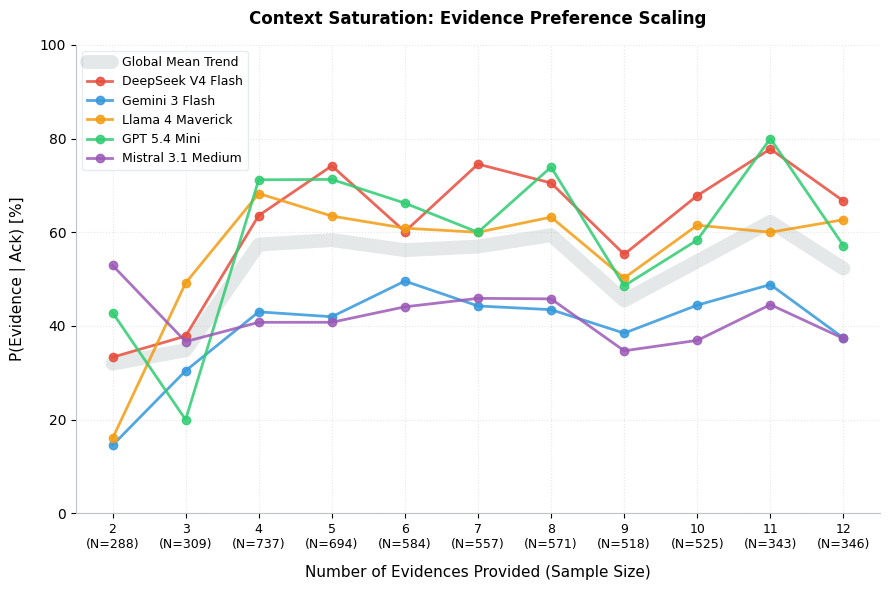

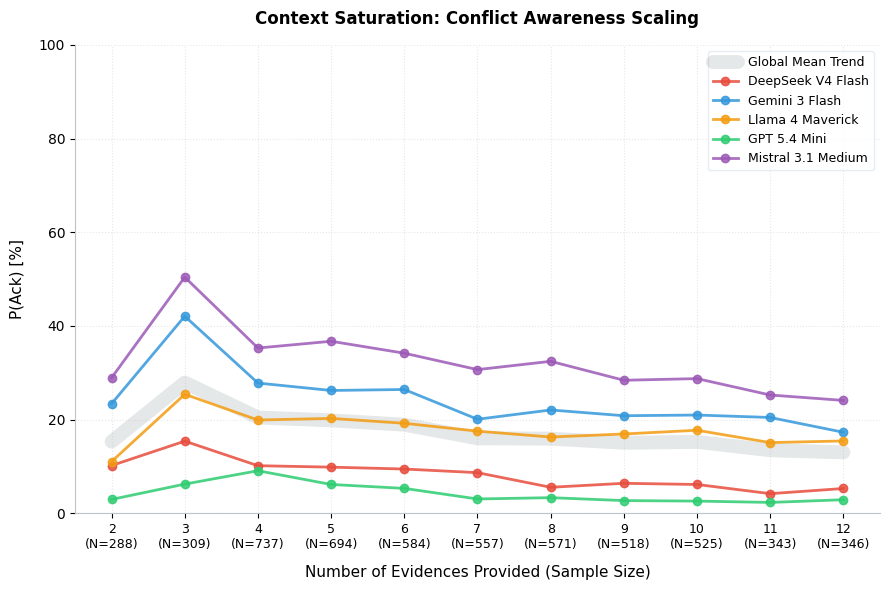

In [662]:
from knowledge_maze.evaluation.metrics.plots.evidence_volume import run_scaling_analysis

run_scaling_analysis()

# Strategy Results Analysis:

Loading evaluation results from: C:\Users\Daniel\Desktop\KnowledgeMaze...
Building strategy dataframe...
Generating Visualizations...


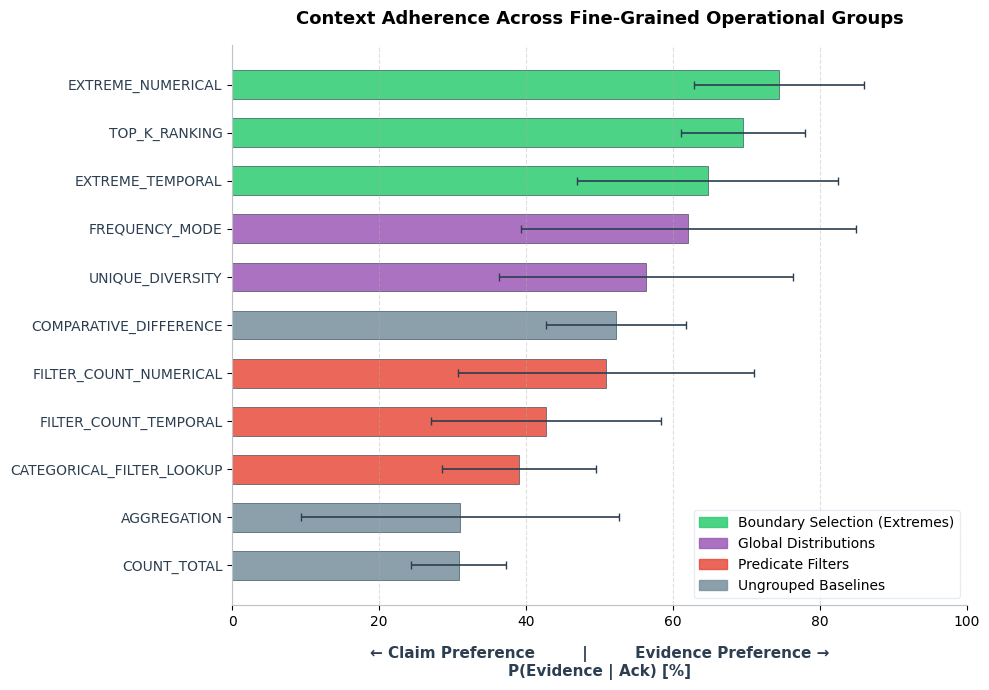

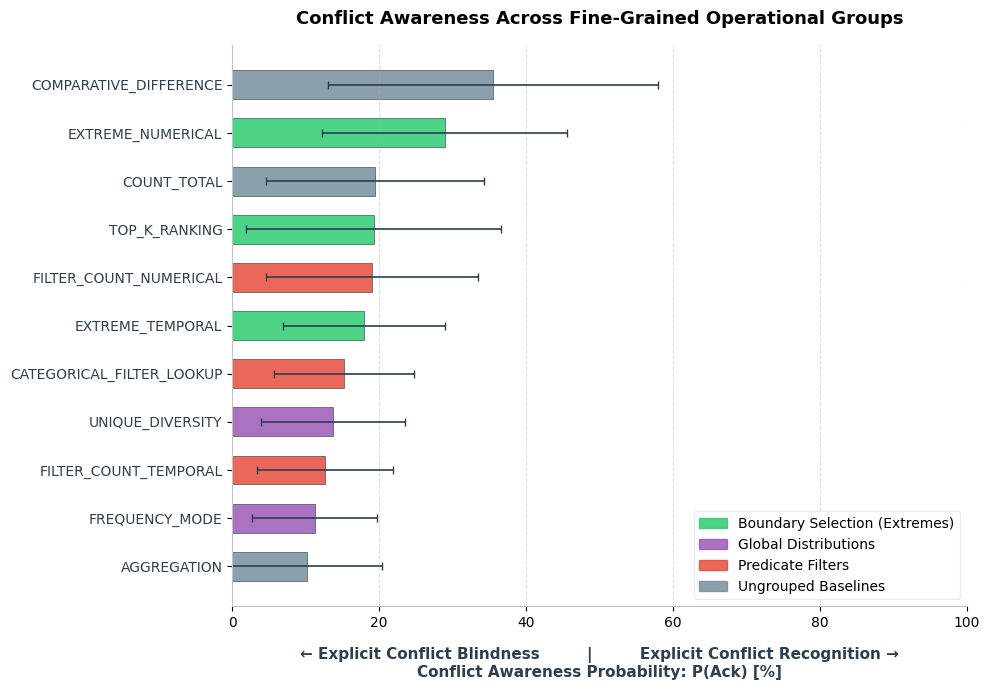

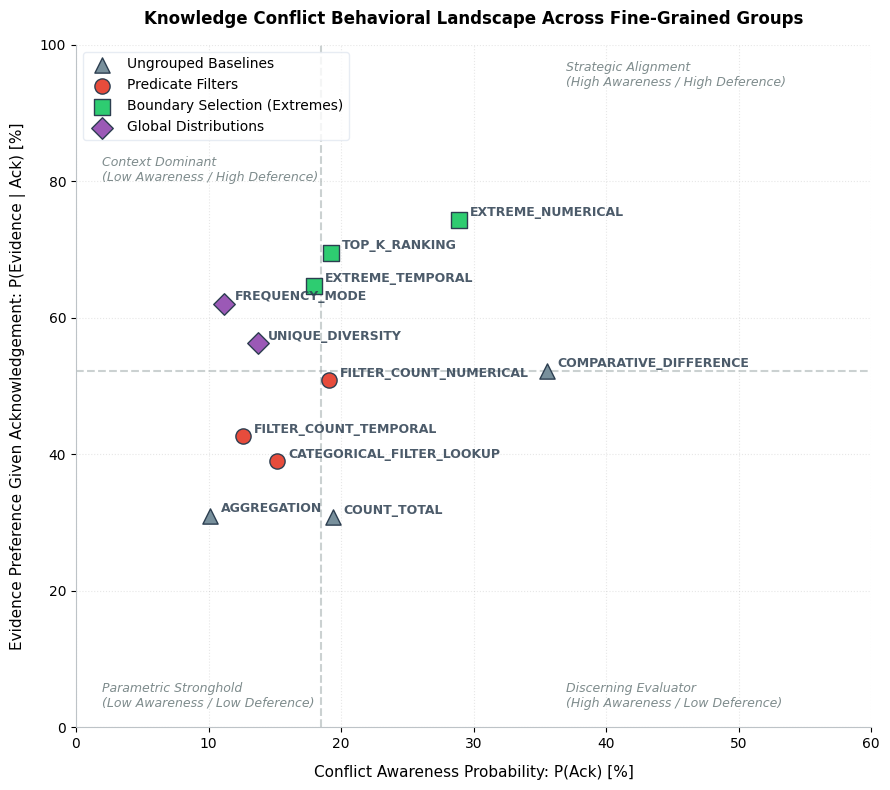

Report generation complete.


In [640]:
from knowledge_maze.evaluation.metrics.plots.strategy import generate_report

generate_report()

## Empirical Findings & Discussion

By mapping reasoning strategies along the dual dimensions of Conflict Awareness ($P(\text{Ack})$) and Conditional Evidence Preference ($P(\text{Evidence} \mid \text{Ack})$), we reveal distinct behavioral profiles that dictate how Large Language Models resolve knowledge conflicts. Our empirical results expose five primary behavioral phenomena across the reasoning taxonomy:

### 1. Ordinal Boundary Selection as a Context Anchor

Strategies within the **Selection and Ranking** family (`EXTREME_NUMERICAL`, `EXTREME_TEMPORAL`, and `TOP_K_RANKING`) consistently occupy the highest tier of conditional evidence preference ($62\%\text{--}74\%$) while maintaining robust conflict awareness ($17\%\text{--}29\%$). Mechanistically, tasks that require the model to scan an entity set and extract an ordinal boundary or extremum natively force strict alignment with the provided context window. This procedural constraint effectively prevents parametric memory drift, ensuring that once a conflict is acknowledged, the model decisively defaults to the contextually provided evidence.

### 2. Attention Diffusion Across Set-Based Operations

Within the **Distributional and Counting Operations** family, we observe a clear inverse relationship between empirical performance and operational complexity:

$$\text{Operational Complexity} \propto \frac{1}{P(\text{Ack})}$$

* **Baseline Cardinality:** Naive set counting (`COUNT_TOTAL`) requires minimal attribute evaluation, preserving the model's tracking capacity and resulting in a healthy baseline awareness score ($20.6\%$). However, its moderate evidence preference ($31\%$) demonstrates that while the model notes the set properties, the simplicity of the tally allows it to frequently defer back to internal weights.
* **Single-Predicate Filtering:** The introduction of conditional boolean constraints (`FILTER_COUNT_TEMPORAL`, `CATEGORICAL_FILTER_LOOKUP`) forces inline state checks on every entity, causing conflict awareness to steadily degrade ($13.7\%\text{--}15.2\%$).
* **Inter-Entity State Tracking:** Complex multi-entity state reductions (`UNIQUE_DIVERSITY`, `FREQUENCY_MODE`) require active global deduplication and frequency mapping. The high cognitive overhead of these tracking loops completely saturates token attention, rendering the model functionally blind to underlying knowledge conflicts ($12.2\%\text{--}13.5\%$ awareness).

### 3. The Temporal-Numerical Asymmetry

A systematic behavioral vector emerges when comparing structurally parallel operations across data domains. Numerical operations undergo a pronounced upward-and-rightward shift on the behavioral landscape relative to their temporal counterparts (e.g., `EXTREME_NUMERICAL` over `EXTREME_TEMPORAL`, and `FILTER_COUNT_NUMERICAL` over `FILTER_COUNT_TEMPORAL`). This divergence points to a fundamental "Fuzzy Time" bias in language models. LLMs possess rigid, highly entrenched parametric memory anchors for timelines, history, and dates. When conflicts disrupt these continuous semantic temporal intervals, the model struggles to detect the discrepancy and easily drifts back to its internal historical priors. Discrete scalar numerical operations, by contrast, trigger cleaner logical-operator pathways that ground more reliably in the context.

### 4. The Cognitive Ceiling of Aggregation

Mathematical synthesis over a closed entity set represents the absolute cognitive ceiling for the evaluated models. The `AGGREGATION` strategy (e.g., computing a mathematical average or summation) yields the lowest conflict awareness ($10.2\%$) and anchors at the lowest evidence preference boundary ($31\%$) in our dataset. When tasked with arithmetic synthesis, the model's generation steps are entirely preoccupied with execution logic. This structural overload disrupts the model's capacity to cross-reference intermediate tokens with its internal weights, leading it to execute the math blindly while defaulting predominantly to pre-trained parametric knowledge.

### 5. Focalized Attention in Comparative Outliers

In stark contrast to complex aggregation, `COMPARATIVE_DIFFERENCE` emerges as a prominent outlier, capturing the highest global conflict awareness score ($34.8\%$). This peak is directly attributable to a highly restricted entity footprint. Because the strategy explicitly isolates and compares exactly *two* target entities over a shared attribute, it creates a highly localized, focalized search space. This narrow scope acts as an immediate attention tripwire, maximizing conflict detection. However, because the task still demands an active mathematical calculation (computing a numerical difference), the post-acknowledgement evidence preference remains bounded at a moderate equilibrium ($52\%$).

---

### Summary of Behavioral Archetypes

| Behavioral Archetype | Representative Strategies | Conflict Awareness ($P(\text{Ack})$) | Evidence Preference ($P(\text{Ev} \mid \text{Ack})$) | Cognitive Profile |
| --- | --- | --- | --- | --- |
| **Context-Grounding** | `EXTREME_NUMERICAL`, `TOP_K_RANKING` | **High** ($18\%\text{--}29\%$) | **Maximum** ($65\%\text{--}74\%$) | Ordinal constraints anchor attention directly to the context window. |
| **Parametric Stronghold** | `AGGREGATION`, `COUNT_TOTAL` | **Low** ($10\%\text{--}20\%$) | **Minimum** ($\approx 31\%$) | Complex synthesis blocks conflict validation, triggering fallback to internal priors. |
| **Discerning Evaluator** | `COMPARATIVE_DIFFERENCE` | **Maximum** ($34.8\%$) | **Moderate** ($\approx 52\%$) | Strict two-entity footprints act as an explicit attention tripwire. |